<a href="https://colab.research.google.com/github/EberHernandezBenitez/Simulacion-II/blob/main/SIR_con_Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo SIR con metropolis.

**El modelo SIR** es un sistema de ecuaciones diferenciales utilizado en epidemiología para simular y predecir cómo se propaga una enfermedad infecciosa dentro de una población a lo largo del tiempo.El modelo asume que la población total ($N$) es constante y la divide en tres compartimentos o estados mutuamente excluyentes:

*  **S (Susceptibles)**: Individuos sanos que no tienen la enfermedad y son vulnerales a contraerla.
*   **I (Infectados)**: Individuos que actualmente tienen la enfermedad y pueden transmitirla a los susceptibles.
*   **R (Recuperados o Removidos)**: Individuos que superaron la enfermedad y adquirieron inmunidad permanente, o bien que fallecieron. En ambos casos, ya no pueden infectarse ni contagiar a otros.\

Formulación Matemática:El flujo de personas entre estos tres estados se describe mediante el siguiente sistema de ecuaciones diferenciales ordinarias (EDO) respecto al tiempo ($t$):









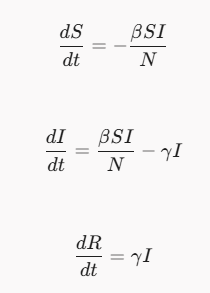

Los parámetros que gobiernan estas tasas de cambio son:$\beta$ (Tasa de transmisión o contacto): Representa la probabilidad de que el contacto entre un individuo susceptible y uno infectado resulte en una nueva infección.$\gamma$ (Tasa de recuperación): Representa la proporción de individuos infectados que se recuperan por unidad de tiempo. Su inverso, $1/\gamma$, equivale al tiempo promedio que una persona es contagiosa.

In [19]:
import numpy as np

import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

In [20]:
# Definir el sistema de ecuaciones diferenciales del modelo SIR

def modelo_sir(t, y, a, b):

    S, I, R = y

    dSdt = -a * S * I
    dIdt = a * S * I - b * I

    dRdt = b * I

    return [dSdt, dIdt, dRdt]

In [21]:
def log_posterior(theta, t_data, I_data, N):
    a, b = theta

    # Restricción física: los parámetros no pueden ser negativos
    if a < 0 or b < 0:
        return -np.inf

    # Condiciones iniciales de la población del internado (N = 763, I(0) = 1)
    S0 = N - I_data[0]
    I0 = I_data[0]
    R0 = 0.0
    y0 = [S0, I0, R0]

    t_span = (t_data[0], t_data[-1])
    try:
        sol = solve_ivp(modelo_sir, t_span, y0, args=(a, b), t_eval=t_data)
        if not sol.success or len(sol.y[1]) != len(I_data):
            return -np.inf
        I_pred = sol.y[1]
    except:
        return -np.inf

    # Likelihood con error gaussiano
    sigma_error = 10.0  # Desviación estándar estimada para los datos del internado
    sse = np.sum((I_data - I_pred)**2)
    log_lik = -len(I_data) / 2 * np.log(2 * np.pi * sigma_error**2) - sse / (2 * sigma_error**2)

    return log_lik


def f(a, b, t_data, I_data, N):
    lp = log_posterior([a, b], t_data, I_data, N)
    return np.exp(lp) if not np.isinf(lp) else 0.0

In [22]:
def metropolis_hastings_sir(n_iter, X_inicial, t_data, I_data, N, sigma_prop=0.0001):

    X_t = list(X_inicial) # X_t = [a, b]

    muestras = [X_t]

    f_x = f(X_t[0], X_t[1], t_data, I_data, N)


    for t in range(1, n_iter):
# Propuesta candidata con caminata aleatoria normal

        z1 = np.random.normal(0, sigma_prop)

        z2 = np.random.normal(0, sigma_prop / 10.0) # Ajuste fino para b

        Y = [X_t[0] + z1, X_t[1] + z2]

        f_y = f(Y[0], Y[1], t_data, I_data, N)

        a_prob = min(f_y / f_x, 1.0) if f_x > 0 else 0.0

        u = np.random.uniform(0, 1)

        if u < a_prob:

            X_t = Y
            f_x = f_y

        muestras.append(list(X_t))

    return np.array(muestras)

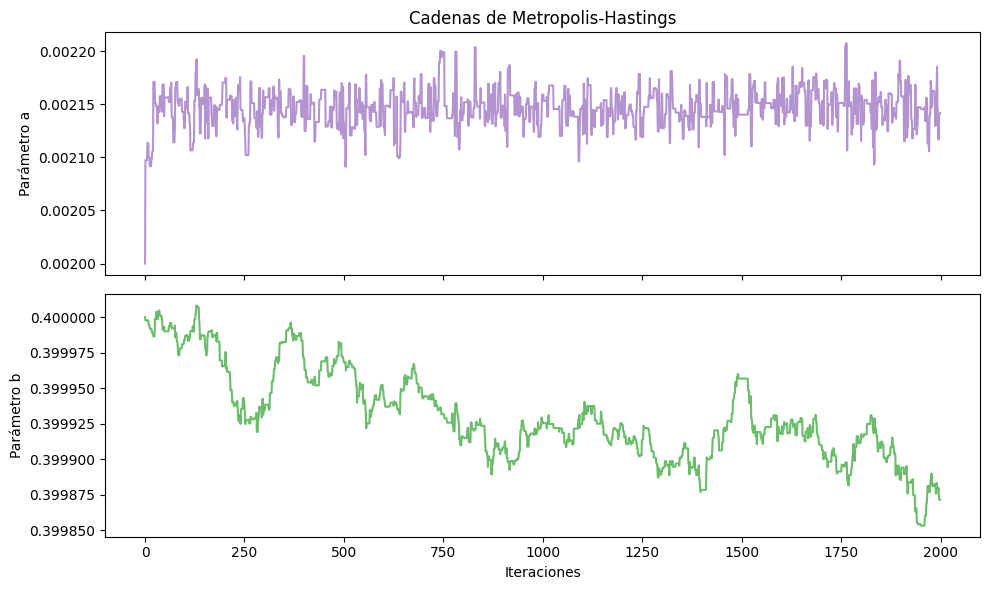

In [23]:
# Datos reales de la investigación (Influenza en un internado)
t_data = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14])
I_data = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])
N = 763  # Población total de estudiantes en el internado

# Parámetros iniciales
n_iteraciones = 2000
X_ini = [0.002, 0.4]
sigma_candidato = 0.00005

# Ejecutar la simulación M-H
cadenas = metropolis_hastings_sir(n_iteraciones, X_ini, t_data, I_data, N, sigma_prop=sigma_candidato)

# Grafica de la evolución de las cadenas de Markov para 'a' y 'b'
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].plot(cadenas[:, 0], color='tab:purple', alpha=0.7)
axes[0].set_ylabel("Parámetro a")
axes[0].set_title("Cadenas de Metropolis-Hastings")
axes[1].plot(cadenas[:, 1], color='tab:green', alpha=0.7)
axes[1].set_ylabel("Parámetro b")
axes[1].set_xlabel("Iteraciones")
plt.tight_layout()
plt.show()

Parámetros óptimos estimados por Metropolis-Hastings:
a: 0.00215
b: 0.39992


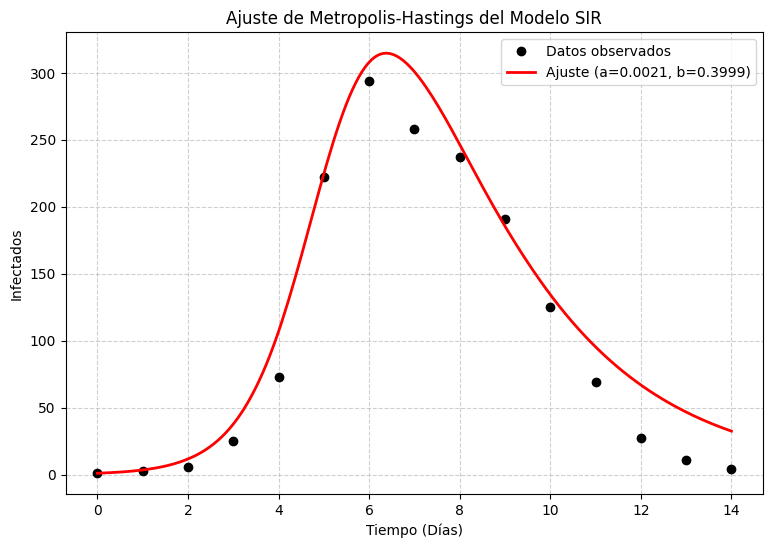

In [24]:
#1. un 20% de los datos iniciales
burn_in = int(n_iteraciones * 0.2)
cadenas_validas = cadenas[burn_in:]

# 2. Obtener los parámetros estimados (usando la media de las muestras válidas)
a_opt = np.mean(cadenas_validas[:, 0])
b_opt = np.mean(cadenas_validas[:, 1])
print(f"Parámetros óptimos estimados por Metropolis-Hastings:")
print(f"a: {a_opt:.5f}")
print(f"b: {b_opt:.5f}")

# 3. Resolver el modelo SIR usando los parámetros óptimos para una curva suave
t_fino = np.linspace(t_data[0], t_data[-1], 200)
S0 = N - I_data[0]
I0 = I_data[0]
R0 = 0.0
y0 = [S0, I0, R0]
sol_opt = solve_ivp(modelo_sir, (t_data[0], t_data[-1]), y0, args=(a_opt, b_opt), t_eval=t_fino)
t_fit = sol_opt.t
I_fit = sol_opt.y[1]
plt.figure(figsize=(9, 6))

# Puntos de los datos observados

plt.plot(t_data, I_data, 'ko', label='Datos observados')
plt.plot(t_fit, I_fit, 'r-', lw=2, label=f'Ajuste (a={a_opt:.4f}, b={b_opt:.4f})')
plt.title('Ajuste de Metropolis-Hastings del Modelo SIR')
plt.xlabel('Tiempo (Días)')
plt.ylabel('Infectados')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Con este código logramos aproximar la solución de las ecuaciones del modelo SIR y además, se grafico la aproximación dando cierto valor de $\alpha$ y de $\beta$.